In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [3]:
folder_path = './Pruebas/0.7/'

/tmp/ipykernel_8218/4168213731.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


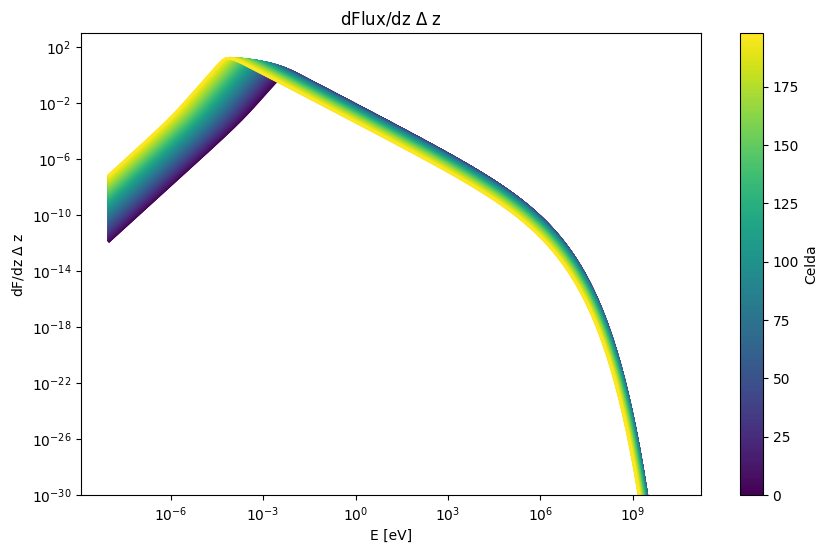

In [4]:


# Cargar los datos
data = np.loadtxt('./../Code/dFlux_dz.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = y_values.shape[1]

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(x, y_values[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-30,1e3)
ax.set_xlabel(r'E [eV]')  # Ajustar según los datos
ax.set_ylabel(r'dF/dz $\Delta$ z')  # Ajustar según los datos
ax.set_title(r'dFlux/dz $\Delta$ z')

plt.show()
# Save the figure
output_path = folder_path + 'dFdz.png'
fig.savefig(output_path, dpi=300)

In [5]:


# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer columnas
E = data[:, 0]  # Primer columna
N = data[:, 1]  # Segunda columna
Z = data[:, 2]  # Tercera columna

data2 = np.loadtxt('./../Code/quant_FF.dat')
# Encontrar valores únicos de E y Z
r=data2[:, 2]
Deltaz=data2[:, -2]

E_unique = np.unique(E)
Z_unique = np.unique(Z)

# Crear una matriz de N con dimensiones (len(E_unique), len(Z_unique))
N_matrix = np.full((len(E_unique), len(Z_unique)), np.nan)  # Usamos NaN para identificar valores faltantes

# Rellenar la matriz
for e, n, z in zip(E, N, Z):
    i = np.where(E_unique == e)[0][0]
    j = np.where(Z_unique == z)[0][0]
    N_matrix[i, j] = n

N_matrix
# Convert the matrix to a DataFrame
df = pd.DataFrame(N_matrix, index=E_unique, columns=Z_unique)

print(E_unique[1])
Deltaz[:]

1.8612468694701466e-06


array([  163.61797689,   136.38222607,   121.7806915 ,   112.7406222 ,
         106.72438375,   102.57095224,    99.66599191,    97.65107775,
          96.30187055,    95.47034075,    95.05473545,    94.98281934,
          95.20197801,    95.67309685,    96.366626  ,    97.25996671,
          98.33568611,    99.58026778,   100.98321871,   102.53641893,
         104.23364013,   106.07018404,   108.04260736,   110.14851003,
         112.3863708 ,   114.75541813,   117.25552838,   119.88714483,
         122.65121293,   125.54912852,   128.58269613,   131.75409549,
         135.06585471,   138.52082874,   142.12218241,   145.87337702,
         149.77816013,   153.84055788,   158.06486951,   162.45566387,
         167.01777749,   171.75631408,   176.67664541,   181.78441321,
         187.08553211,   192.58619357,   198.29287062,   204.21232336,
         210.35160525,   216.71807008,   223.31937964,   230.16351195,
         237.25877026,   244.61379248,   252.2375614 ,   260.13941535,
      

/tmp/ipykernel_8218/3803663465.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis', N)


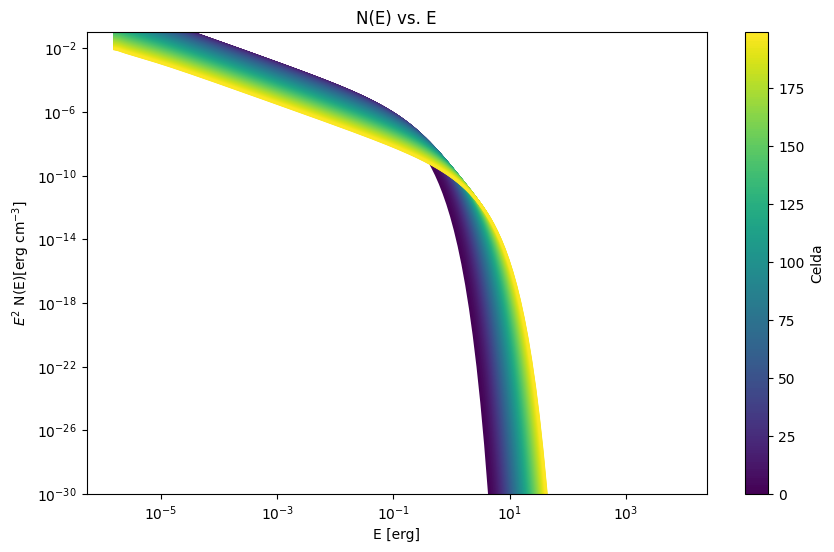

In [6]:
# Cargar los datos
data = np.loadtxt('./../Code/Ne_cuts.dat')

# Extraer el eje x y las columnas de datos
x = data[:, 0]
y_values = data[:, 1:]
# Número de columnas
N = len(Z_unique)

# Crear el colormap Viridis
cmap = cm.get_cmap('viridis', N)
norm = mcolors.Normalize(vmin=0, vmax=N-1)

# Crear la figura y los ejes
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar todas las curvas con colores del colormap
for i in range(N):
    ax.plot(E_unique, E_unique**2*df.iloc[:, i], color=cmap(norm(i)), linewidth=2)

# Agregar la barra de colores
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # Necesario para la colorbar
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Celda')  # Etiqueta de la colorbar

# Etiquetas y título
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(1e-30,1e-1)
ax.set_xlabel(r'E [erg]')  # Ajustar según los datos
ax.set_ylabel(r'$E^2$ N(E)[erg cm$^{-3}$]')  # Ajustar según los datos
ax.set_title(r'N(E) vs. E')

plt.show()

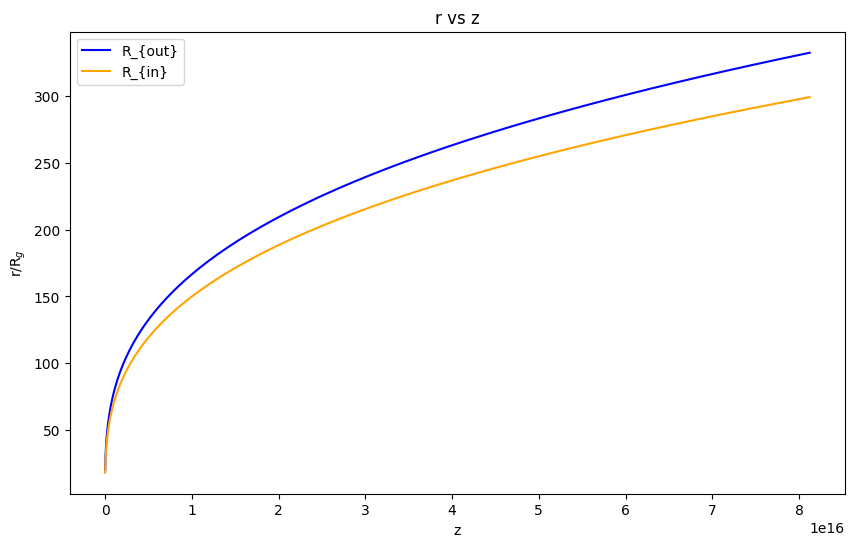

In [7]:
# Extract columns from data2
M_BH = 5.5e7
R_g = 1.477e5*M_BH
Z = data2[:, 0]  # Column 0
r_out = data2[:, 2]  # Column 2
r_in = data2[:, 3]  # Column 3
#print(r_in)
# Plot the data
plt.figure(figsize=(10, 6))
plt.plot(Z, r_out/R_g, label=r'R_{out}', color='blue')
plt.plot(Z, r_in/R_g, label=r'R_{in}', color='orange')
#plt.xscale('log')
#plt.yscale('log')
plt.xlabel('z')
plt.ylabel('r/R$_g$')
plt.title('r vs z')
plt.legend()
# Save the figure
output_path = folder_path + 'r.png'
plt.savefig(output_path, dpi=300)
plt.show()


/tmp/ipykernel_8218/971180683.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


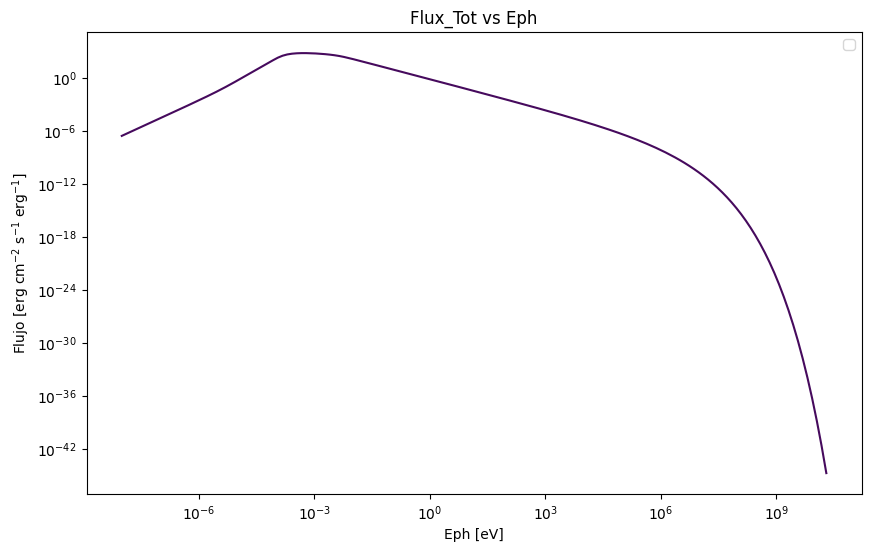

In [8]:
# Read the data from Flux.dat
df_flux = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)
df_flux9 = pd.read_csv('./../Code/Flux.dat', sep='\s+', header=0)
# Plot the first and last column
            
plt.figure(figsize=(10, 6))
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_1'], label='R_max=7.3*R_g')
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_2'], label='R_max=2.6d1*R_g')
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_3'], label='R_max=6.5d1*R_g')
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_4'], label='R_max=1.95d2*R_g')
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_5'], label='R_max=6.5d2*R_g')
# plt.plot(df_flux['Eph/eV'], df_flux['Flujo_6'], label='R_max=3d5*R_g')
plt.plot(df_flux9['Eph/eV'], df_flux9['Flujo_6'], label=r'', linestyle='-', color=cmap(5))
# plt.plot(df_flux7['Eph/eV'], df_flux7['Flujo_Tot'], label=r'$R_{in}=0.7R_o$', linestyle='-', color=cmap(4))
# plt.plot(df_flux5['Eph/eV'], df_flux5['Flujo_Tot'], label=r'$R_{in}=0.5R_o$', linestyle='-', color=cmap(3))
# plt.plot(df_flux3['Eph/eV'], df_flux3['Flujo_Tot'], label=r'$R_{in}=0.3R_o$', linestyle='-', color=cmap(2))
# plt.plot(df_flux1['Eph/eV'], df_flux1['Flujo_Tot'], label=r'$R_{in}=0.1R_o$', linestyle='-', color=cmap(1))
# plt.plot(df_flux0['Eph/eV'], df_flux0['Flujo_Tot'], label=r'$R_{in}=0.3R_g$', linestyle='-', color=cmap(0))

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Eph [eV]')
plt.ylabel('Flujo [erg cm$^{-2}$ s$^{-1}$ erg$^{-1}$]') #Para pasar a Jy multiplicar por h y multiplicar por 1e-26
plt.title('Flux_Tot vs Eph')
#plt.ylim(1e-6, 1e4)
#plt.xlim(1e-7,1e-3)
plt.legend()
# Save the figure
# output_path = folder_path + 'F.png'
# plt.savefig(output_path, dpi=300)
plt.show()


In [10]:
B0 = data2[:, 1]  # Column 2
#B0 #0.3Rg
#B1 #0.1
#B2 #0.3
#B3 #0.5
#B4 #0.7

/tmp/ipykernel_8257/3179241204.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


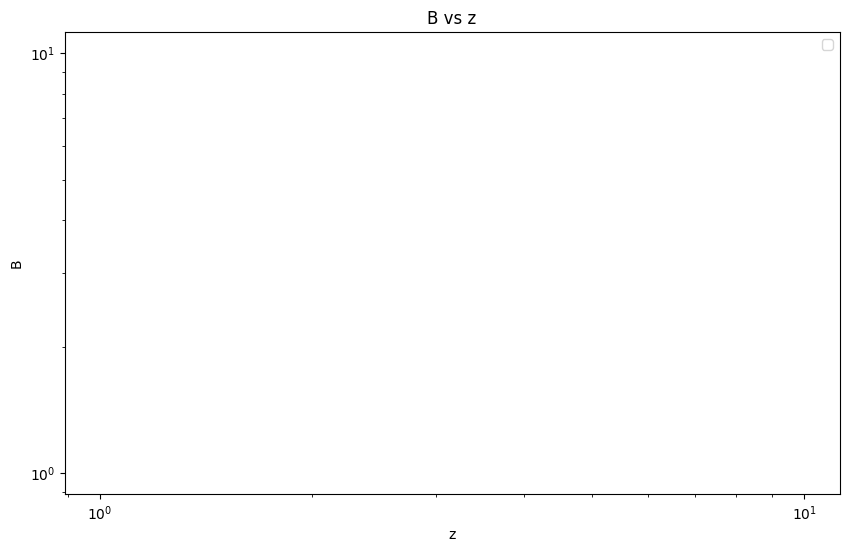

In [11]:
Z = data2[:, 0]  # Column 0
B = data2[:, 1]  # Column 2
plt.figure(figsize=(10, 6))
#plt.plot(Z, B0, label=r'$R_{in}=0.3R_g$', color='blue')
#plt.plot(Z, B1, label=r'R_{in}=0.1R_{out}', color='green')
#plt.plot(Z, B2, label=r'R_{in}=0.3R_{out}', color='orange')
# plt.plot(Z, B3, label=r'R_{in}=0.5R_{out}', color='magenta')
# plt.plot(Z, B4, label=r'R_{in}=0.7R_{out}', color='red')
# plt.plot(Z, B5, label=r'R_{in}=0.9R_{out}', color='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('B')
plt.title('B vs z')
plt.legend()
# Save the figure
output_path = folder_path + 'B.png'
plt.savefig(output_path, dpi=300)
plt.show()


In [15]:
U_e5=data3[:, 2]
# U_e0
# U_e1
# U_e2
# U_e3
# U_e4

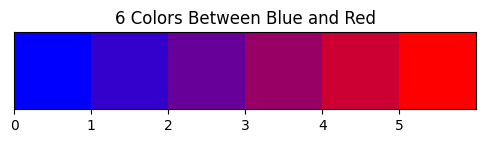

In [16]:
from matplotlib.colors import LinearSegmentedColormap

import matplotlib.pyplot as plt

# Generate a custom colormap from blue to red
cmap = LinearSegmentedColormap.from_list("blue_red", ["blue", "red"], N=6)

# Get the colors
colors = [cmap(i) for i in range(cmap.N)]

# Display the colors
plt.figure(figsize=(8, 1))
plt.imshow([colors], extent=[0, 6, 0, 1])
plt.gca().set_yticks([])
plt.gca().set_xticks(range(6))
plt.title("6 Colors Between Blue and Red")
plt.show()

200


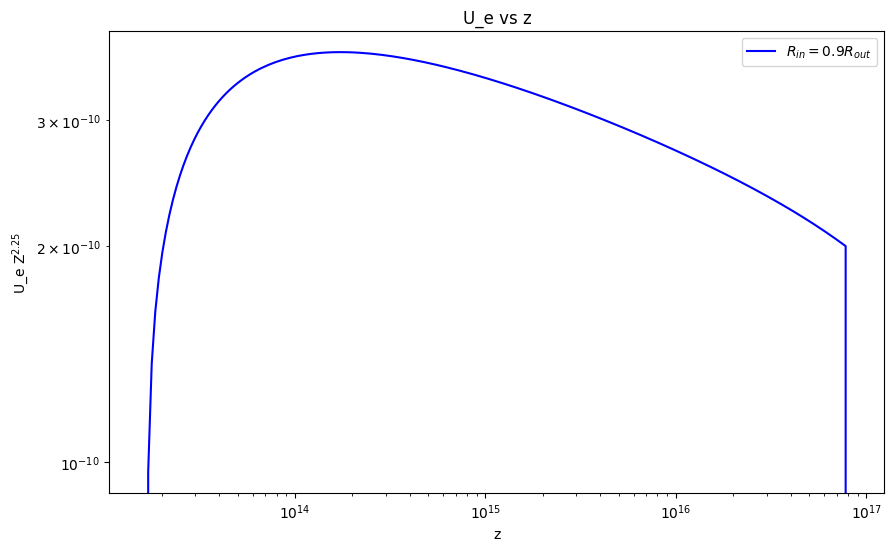

In [17]:
data3 = np.loadtxt('./../Code/U_e.dat')
# Encontrar valores únicos de E y Z
U_e=data3[:, 2]
Z=data3[:, 1]
print(len(Z))
plt.figure(figsize=(10, 6))
# plt.plot(Z, U_e0*Z**2.25, label=r'$R_{in}=0.3R_g$', color=cmap(5))
# plt.plot(Z, U_e1*Z**2.25, label=r'$R_{in}=0.1R_{out}$', color=cmap(4))
# plt.plot(Z, U_e2*Z**2.25, label=r'$R_{in}=0.3R_{out}$', color=cmap(3))
# plt.plot(Z, U_e3*Z**2.25, label=r'$R_{in}=0.5R_{out}$', color=cmap(2))
# plt.plot(Z, U_e4*Z**2.25, label=r'$R_{in}=0.7R_{out}$', color=cmap(1))
plt.plot(Z, U_e5*Z**2.25, label=r'$R_{in}=0.9R_{out}$', color=cmap(0))
plt.xscale('log')
plt.yscale('log')
plt.xlabel('z')
plt.ylabel('U_e Z$^{2.25}$')
plt.title('U_e vs z')
plt.legend()
# # Save the figure
# output_path = folder_path + 'Ue.png'
# plt.savefig(output_path, dpi=300)
plt.show()


In [18]:
# Read the file using pandas
df_dflux_dz = pd.read_csv('./../Code/dFlux_dz.dat', delim_whitespace=True, header=None)

# Extract the first column as a vector E
E = df_dflux_dz.iloc[:, 0].values

# Extract the other columns as a DataFrame
df_data = df_dflux_dz.iloc[:, 1:]

# Integrate each column over the vector E
integrated_values1 = df_data.apply(lambda col: np.trapz(col, E), axis=0)
# integrated_values0
# integrated_values1
# integrated_values2
# integrated_values3
# integrated_values4

/tmp/ipykernel_8257/3080623445.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_dflux_dz = pd.read_csv('./../Code/dFlux_dz.dat', delim_whitespace=True, header=None)
/tmp/ipykernel_8257/3080623445.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integrated_values1 = df_data.apply(lambda col: np.trapz(col, E), axis=0)


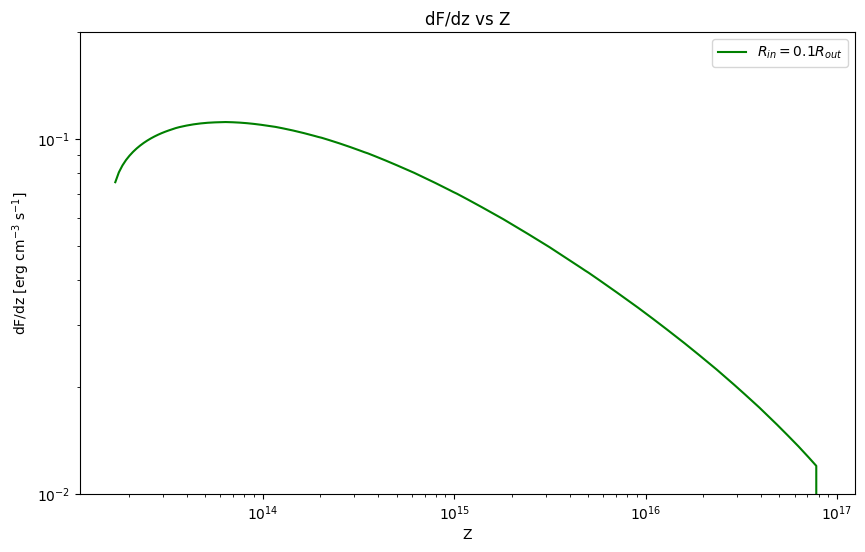

In [19]:

plt.figure(figsize=(10, 6))
# plt.plot(Z[1:], integrated_values0, label=r'$R_{in}=0.3R_g$', color='blue')
plt.plot(Z[1:], integrated_values1, label=r'$R_{in}=0.1R_{out}$', color='green')
# plt.plot(Z[1:], integrated_values2, label=r'$R_{in}=0.3R_{out}$', color='orange')
# plt.plot(Z[1:], integrated_values3, label=r'$R_{in}=0.5R_{out}$', color='magenta')
# plt.plot(Z[1:], integrated_values4, label=r'$R_{in}=0.7R_{out}$', color='red')
# plt.plot(Z[1:], integrated_values5, label=r'$R_{in}=0.9R_{out}$', color='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Z')
plt.ylabel('dF/dz [erg cm$^{-3}$ s$^{-1}$]')
plt.ylim(1e-2,0.2e0)
plt.title('dF/dz vs Z')
plt.legend()
# Save the figure
output_path = folder_path + 'dF(integrado).png'
plt.savefig(output_path, dpi=300)
plt.show()

